In [20]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [21]:
check1_results = np.load("robustness_results/check1_Nr_x_overlap.npz", allow_pickle=True)
check2_results = np.load("robustness_results/check2_correlation.npz", allow_pickle=True)
check3_results = np.load("robustness_results/check3_burst_size.npz", allow_pickle=True)
check4_results = np.load("robustness_results/check4_trait_distributions.npz", allow_pickle=True)
check5_results = np.load("robustness_results/check5_carbon_ratio.npz", allow_pickle=True)

In [22]:
## comment out if stylefile not present
plt.style.use("../../style2.mplstyle")

### Panel A - Check whether diversity increase is larger in SW than in PE

In [23]:
def get_delta_hill(data):
    """Extract ΔHill_SW and ΔHill_PE from a robustness result array."""
    dsw = data[:, 1, 2] - data[:, 0, 2]
    dpe = data[:, 3, 2] - data[:, 2, 2]
    return dsw, dpe

configs = [
    (check1_results, "Nr6_lowOverlap",   "Fewer resources in pollen"),
    (check2_results, "corr_-0.5", "Fast growers are phage resistant"),
    (check2_results, "corr_0.9",  "Fast growers are phage susceptible"),
    (check3_results, "beta_5",   r"Low burst size ($\beta$ = 5)"),
    (check3_results, "beta_100", r"High burst size ($\beta$ = 100)"),
    (check4_results, "mmg_-2_mmi_-2", "Slow growth, high susceptibility"),
    (check4_results, "mmg_0_mmi_-4",  "Fast growth, low susceptibility"),
    (check5_results, "carbon_ratio_0.5", "Half carbon in pollen"),
    (check5_results, "carbon_ratio_2.0", "Double carbon in pollen"),
]

groups = [
    ("Nr × overlap", 0, 2),
    ("Growth-defense", 2, 4),
    ("Burst size", 4, 6),
    ("Trait scale", 6, 8),
    ("Carbon ratio", 8, 10),
]

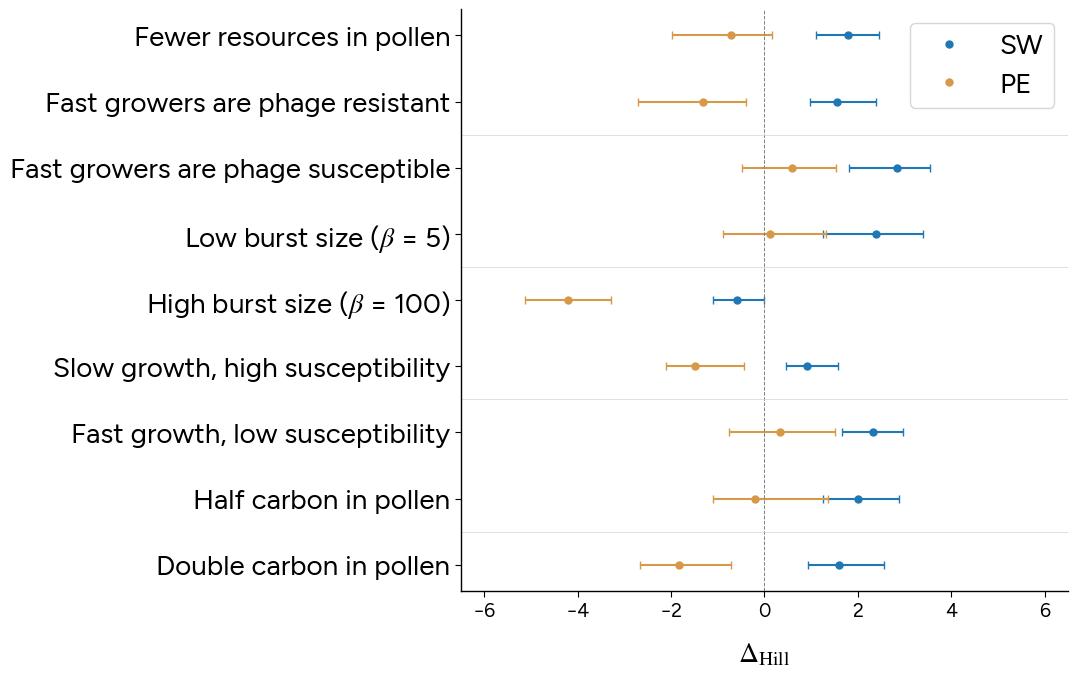

In [26]:
fig, ax = plt.subplots(figsize=(11, 7))

for i, (src, key, label) in enumerate(configs):
    dsw, dpe = get_delta_hill(src[key])

    non_nan_indices = ~np.isnan(dsw) & ~np.isnan(dpe)
    dsw = dsw[non_nan_indices]
    dpe = dpe[non_nan_indices]

    med_sw, q25_sw, q75_sw = np.median(dsw), np.percentile(dsw, 25), np.percentile(dsw, 75)
    med_pe, q25_pe, q75_pe = np.median(dpe), np.percentile(dpe, 25), np.percentile(dpe, 75)

    y = len(configs) - 1 - i 

    ax.errorbar(med_sw, y, xerr=[[med_sw - q25_sw], [q75_sw - med_sw]],
                fmt='o', color="#1f78b4", markersize=5, capsize=3, zorder=2)

    ax.errorbar(med_pe, y, xerr=[[med_pe - q25_pe], [q75_pe - med_pe]],
                fmt='o', color="#d79848", markersize=5, capsize=3, zorder=2)

ax.axvline(0, color='gray', linestyle='--', linewidth=0.7)

ax.set_xlim(-6.5,6.5)
ax.set_yticks(range(len(configs)))
ax.set_yticklabels([c[2] for c in configs][::-1], fontsize=20)

for gname, gstart, gend in groups:
    y_sep = len(configs) - gstart - 0.5
    if gstart > 0:
        ax.axhline(y_sep, color='lightgray', linewidth=0.5)

ax.set_xlabel(r'$\Delta_{\mathrm{Hill}}$',fontsize=20)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

from matplotlib.lines import Line2D
ax.legend(
    handles=[
        Line2D([0], [0], marker='o', color="#1f78b4", linestyle='', markersize=5, label='SW'),
        Line2D([0], [0], marker='o', color="#d79848", linestyle='', markersize=5, label='PE'),
    ],
    loc='upper right', frameon=True, fontsize=20
)

plt.tight_layout()
# plt.savefig("figures/SI/test1.svg", dpi=300, bbox_inches='tight')
plt.show()

## Panel B - Check whether oscillations increase is more in SW than in PE

In [27]:
def get_delta_osc(data):
    """Log10 fold-change in oscillation score due to phages."""
    osc_sw_no = data[:, 0, 4]
    osc_sw_ph = data[:, 1, 4]
    osc_pe_no = data[:, 2, 4]
    osc_pe_ph = data[:, 3, 4]
    # Floor to avoid log(0)
    floor = 1e-12
    dsw = np.log10(np.maximum(osc_sw_ph, floor)) - np.log10(np.maximum(osc_sw_no, floor))
    dpe = np.log10(np.maximum(osc_pe_ph, floor)) - np.log10(np.maximum(osc_pe_no, floor))
    return dsw, dpe

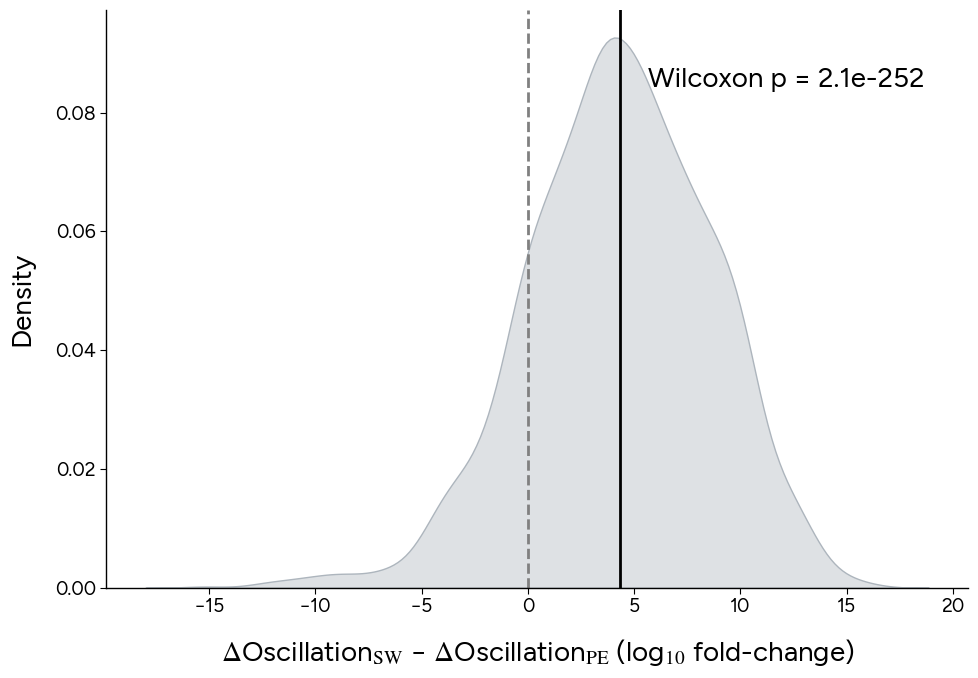

In [ ]:
all_diff = []
for src, keys in [
    (check1_results, ["Nr6_lowOverlap",  "Nr30_lowOverlap"]),
    (check2_results, ["corr_-0.5", "corr_0.0", "corr_0.5", "corr_0.9"]),
    (check3_results, ["beta_5", "beta_10", "beta_50", "beta_100"]),
    (check4_results, [f"mmg_{int(mg)}_mmi_{int(mi)}" for mg in [-2,-1,0] for mi in [-4,-3,-2]]),
    (check5_results, ["carbon_ratio_0.5", "carbon_ratio_1.0", "carbon_ratio_2.0"]),
]:
    for key in keys:
        data = src[key]
        dsw, dpe = get_delta_osc(data)
        non_nan_indices = ~np.isnan(dsw) & ~np.isnan(dpe)
        dsw = dsw[non_nan_indices]
        dpe = dpe[non_nan_indices]
        all_diff.extend(dsw - dpe)

all_diff = np.array(all_diff)
all_diff = all_diff[~np.isnan(all_diff)]

stat, p = stats.wilcoxon(all_diff)

fig, ax = plt.subplots(figsize=(10,7))
sns.kdeplot(all_diff, ax=ax, fill=True, color='#adb5bd', alpha=0.4)
ax.axvline(0, color='gray', linestyle='--', linewidth=2)
ax.axvline(np.median(all_diff), color='black', linestyle='-', linewidth=2)
ax.text(0.95, 0.9, f'Wilcoxon p = {p:.1e}',
        transform=ax.transAxes, ha='right', va='top', fontsize=20)
ax.set_xlabel(r'$\Delta$Oscillation$_{\mathrm{SW}}$ − $\Delta$Oscillation$_{\mathrm{PE}}$ (log$_{10}$ fold-change)', fontsize=20)
ax.set_ylabel('Density', fontsize=20)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
# plt.savefig("figures/SI/test2.svg", dpi=300, bbox_inches='tight')
plt.show()

## Panel C - Are $\Delta_{SW}$ and $\Delta_{PE}$ always correlated?

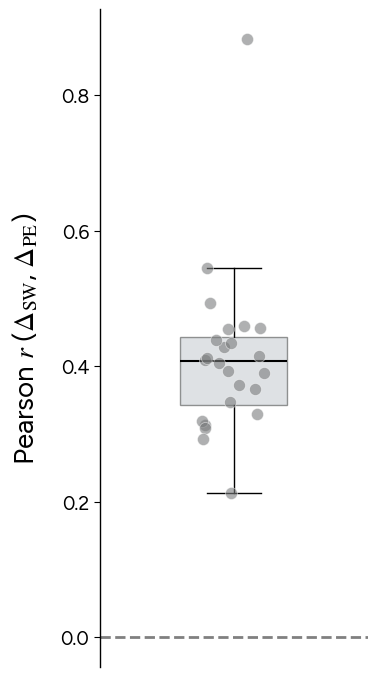

In [29]:
all_rs = []
all_ps = []
for src, keys in [
    (check1_results, ["Nr6_lowOverlap", "Nr6_highOverlap", "Nr30_lowOverlap", "Nr30_highOverlap"]),
    (check2_results, ["corr_-0.5", "corr_0.0", "corr_0.5", "corr_0.9"]),
    (check3_results, ["beta_5", "beta_10", "beta_50", "beta_100"]),
    (check4_results, [f"mmg_{int(mg)}_mmi_{int(mi)}" for mg in [-2,-1,0] for mi in [-4,-3,-2]]),
    (check5_results, ["carbon_ratio_0.5", "carbon_ratio_1.0", "carbon_ratio_2.0"]),
]:
    for key in keys:
        data = src[key]
        dsw = data[:, 1, 2] - data[:, 0, 2]
        dpe = data[:, 3, 2] - data[:, 2, 2]
        mask = ~(np.isnan(dsw) | np.isnan(dpe))
        if mask.sum() >= 5:
            r, p = stats.pearsonr(dsw[mask], dpe[mask])
            all_rs.append(r)
            all_ps.append(p)

all_rs = np.array(all_rs)
all_ps = np.array(all_ps)
sig = all_ps < 0.05
n_sig = np.sum(sig)

fig, ax = plt.subplots(figsize=(4, 7))

bp = ax.boxplot(all_rs, vert=True, widths=0.4, patch_artist=True,
                boxprops=dict(facecolor="#adb5bd", alpha=0.4),
                medianprops=dict(color='black', linewidth=1.5),
                showfliers=False,zorder=1)

jitter = np.random.uniform(-0.12, 0.12, len(all_rs))

# Significant: filled
ax.scatter(np.ones(np.sum(sig)) + jitter[sig], all_rs[sig],
           color="#7a7c7d", s=75,edgecolors='white', linewidth=0.5,
           label=f'p < 0.05 ({n_sig}/{len(all_rs)})',alpha=0.6,zorder=10)
# Non-significant: hollow
ax.scatter(np.ones(np.sum(~sig)) + jitter[~sig], all_rs[~sig],
           facecolors='none', edgecolors='#adb5bd', s=75, zorder=3, linewidth=1.2,
           label=f'n.s. ({len(all_rs) - n_sig}/{len(all_rs)})')

ax.axhline(0, color='gray', linestyle='--', linewidth=2)

ax.set_ylabel(r'Pearson $r$ ($\Delta_{\mathrm{SW}}$, $\Delta_{\mathrm{PE}}$)', fontsize=20)
ax.set_xticks([])
# ax.legend(loc='upper left', frameon=True, fontsize=14)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
plt.tight_layout()
# plt.savefig("figures/SI/test3.svg", dpi=300, bbox_inches='tight')
plt.show()